# SLU07 - Regression With Linear Regression: Exercise notebook

In the learning notebook we have presented you with several new concepts. 

With this exercise notebook we want to take a closer look at some of the formulas we introduced in the learning notebook and help you understand the concepts from a more practical experience.

Let's dive right into it and enjoy the ride!

![ride](media/ride.gif)

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

plt.rcParams["figure.figsize"]=(4.8, 3.6)
np.random.seed(42)

## Exercise 1 - Simple Linear Regression

As a first exercise, let's imagine you're thinking about changing your career and now you want to become a full-time blogger (I know that in these days, bloggers are not a thing but let's assume it is).

![blog](media/blog.gif)

Although being a full-time blogger seems to be a lot of fun, you need to have a sense of how much money you will make with the blog so you can manage your financial life. 

After doing some online research, you find income reports of full-time bloggers and you put that information into a spreadsheet. This spreadsheet has information about the number of months of blogging experience and the corresponding amount of money earned.

You will use this dataset to predict approximately how much money can be earned based on the number of months of blogging experience.

You probably already have a hunch that, the older a blog is, the more money it makes, but by using linear regression you’ll be able to support or refute this hypothesis with actual data. You know, the kind of data you can take to the bank.

In [2]:
df_blog = pd.read_csv('data/blogging_income.csv')
df_blog.head()

,MonthsExperience,Income
0,3,424
1,3,387
2,3,555
3,4,590
4,4,533


Let's start by visualizing the data:

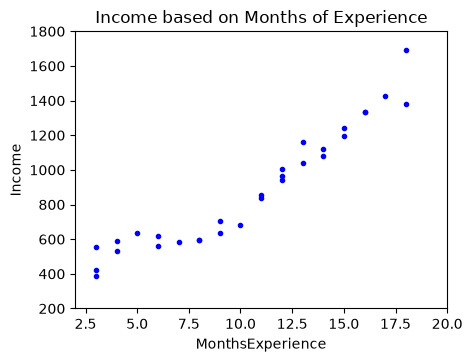

In [3]:
df_blog = df_blog.sort_values('MonthsExperience')
plt.xlim((2, 20))
plt.ylim((200, 1800))
plt.xlabel('MonthsExperience')
plt.title('Income based on Months of Experience')
plt.ylabel('Income')
plt.plot(df_blog['MonthsExperience'], df_blog['Income'], 'b.')
plt.show()

### Exercise 1.1 - Simple Linear Model

As you can see, our data has only one variable ($x$: 'Months of Experience') and one label ($y$: 'Income'), so we can try to fit it with a simple linear regression. This model is represented by the following expression:

$$\hat{y} = \beta_0 + \beta_1 x$$

where $\hat{y}$ are the predictions, $\beta_0$ is the intercept, $\beta_1$ is the coefficient and $x$ is the input sample. Expanding to several samples, we can write this equation in a vector form:

$$\vec{\hat{y}} = \beta_0\vec{1} + \beta_1 \vec{x}$$

In this exercise, we would like you to implement the function <em>simple_linear_regression</em>, which should compute the output of the equation above:

Ensure that the f1_1, f2_1, and y_hat1 in the first assert are floats.

In [4]:
def simple_linear_regression(x, betas):
    """
    Args:
        x : numpy.array with shape (num_samples,) - The input data
        betas: numpy.array with shape (2,) - parameters of the model [b_0, b_1]
    
    Returns:
        f1, f2 : numpy.array with shape (num_samples,) - intermediate calculations
        y_hat : numpy.array with shape (num_samples,) - The prediction made by 
                the simple linear regression.
    """
    
    # Let's begin with the first term of the equation
    # f1 = ...
    # YOUR CODE HERE
    f1 = betas[0] * np.ones(x.shape[0])
    
    # Now, the second term
    # f2 = ...
    # YOUR CODE HERE
    f2 = betas[1] * x
    
    # Now let's sum the two terms of the equation
    # y_hat = ...
    # YOUR CODE HERE
    y_hat = f1 + f2
    
    return f1, f2, y_hat

In [5]:
# Simple test
f1_1, f2_1, y_hat1 = simple_linear_regression(np.arange(0, 5), np.array([-15, 20]))
assert isinstance(f1_1,np.ndarray), 'f1_1 should be a numpy array'
assert isinstance(f2_1,np.ndarray), 'f2_1 should be a numpy array'
assert isinstance(y_hat1,np.ndarray), 'y_hat1 should be a numpy array'
assert f1_1.shape==(5,), 'The shape of f1_1 is not correct.'
assert f2_1.shape==(5,), 'The shape of f2_1 is not correct.'
assert y_hat1.shape==(5,), 'The shape of y_hat1 is not correct.'
assert hashlib.sha256(''.join([str(float(i)) for i in f1_1]).encode('utf-8')).hexdigest() == \
'cea1134cb91f64b3115314832605f52301489493e50b9d68b26a127e269b0f9f', "Perhaps your f1 variable is not well calculated!"
assert hashlib.sha256(''.join([str(float(i)) for i in f2_1]).encode('utf-8')).hexdigest() == \
'7b5c77635d12c0effb79b027441923a93a3cceecd4311110493e42a7146fb3cb', "Perhaps your f2 variable is not well calculated!"
assert hashlib.sha256(''.join([str(float(i)) for i in y_hat1]).encode('utf-8')).hexdigest() == \
'1f9889fe39dad0bec2c25537846a49bd88d1943ad9c79e760fd6552029c5cfb4', "Perhaps your y_hat variable is not well calculated!"

# Test using our dataset
f1_2, f2_2, y_hat2 = simple_linear_regression(df_blog['MonthsExperience'].to_numpy(),np.array([3.0, 2.5]))
assert isinstance(f1_2,np.ndarray), 'f1_2 should be a numpy array'
assert isinstance(f2_2,np.ndarray), 'f2_2 should be a numpy array'
assert isinstance(y_hat2,np.ndarray), 'y_hat2 should be a numpy array'
assert f1_2.shape==(30,), 'The shape of f1_2 is not correct.'
assert f2_2.shape==(30,), 'The shape of f2_2 is not correct.'
assert y_hat2.shape==(30,), 'The shape of y_hat2 is not correct.'
assert hashlib.sha256(''.join([str(float(i)) for i in f1_2]).encode('utf-8')).hexdigest() == \
'813da1018ad40a91070c69f05e642b36345d4cae740bd47b03ca12d1ba96a586', "Perhaps your f1 variable is not well calculated!"
assert hashlib.sha256(''.join([str(float(i)) for i in f2_2]).encode('utf-8')).hexdigest() == \
'5abc33114cbddc5f935f11fe481597f2983f3ad2cb3e1a24891d4859c7c77f06', "Perhaps your f2 variable is not well calculated!"
assert hashlib.sha256(''.join([str(float(i)) for i in y_hat2]).encode('utf-8')).hexdigest() == \
'0546bb6076f6a41d155e8a69a247effa6f16ed1201b3a630d9458faa559f5d08', "Perhaps your y_hat variable is not well calculated!"

Now that you have a function to construct the model, the next step is to discover the values of the betas.

The first approach you can take is to implement the closed form solution. That is, solving the equation that minimizes the error across all of the samples - ordinary least squares. For that, however, we need to implement a function calculating the error. We'll use the cost function that you have learned about.

### Exercise 1.2 Cost Function

Implement the mean-squared-error cost function

$$J = \frac{1}{N} \sum_{n=1}^N e_i^2 = \frac{1}{N} \sum_{n=1}^N (y_i - \hat{y_i})^2$$

where the error, $e_i$, is the difference between your prediction and the actual sample value.

In [6]:
def cost_function(y, y_hat):
    """
    Args: 
        y : numpy.array with shape (num_samples, ) - real values
        y_hat : numpy.array  with shape (num_samples, ) - predicted values
    
    Returns:
        mean_squared_error : float
    """
    
    # Compute the error
    # error = ...
    # YOUR CODE HERE
    error = y - y_hat
    
    # Now, square the difference
    # squared_error = ...
    # YOUR CODE HERE
    squared_error = error ** 2
    
    # Finally, take the mean and return the mean sqared error
    # mean_squared_error = ...
    # YOUR CODE HERE
    mean_squared_error = squared_error.mean()
    
    return mean_squared_error

In [7]:
# Simple tests
np.testing.assert_almost_equal(cost_function(np.array([.24]), np.array([.36])), 0.0144)
np.testing.assert_almost_equal(cost_function(np.array([1.13]), np.array([2.65])), 2.3104)

# Test using our dataset
x_rnd = df_blog['MonthsExperience'].to_numpy()
y_rnd = df_blog['Income'].to_numpy()
beta_rnd = np.array([120, 120])
_, _,y_hat_rnd = simple_linear_regression(x_rnd, beta_rnd)

np.testing.assert_almost_equal(cost_function(y_rnd, y_hat_rnd), 294785.2)

As you can see from the previous test, picking just random values for the betas will probably yield very high error values. You can even visualize this to see that, in fact, these random betas don't fit our data:

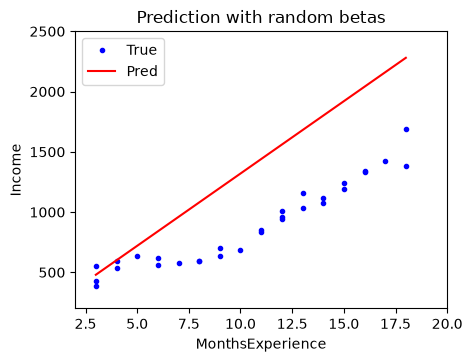

In [8]:
plt.xlim((2, 20))
plt.ylim((200, 2500))
plt.xlabel('MonthsExperience')
plt.ylabel('Income')
plt.title('Prediction with random betas')
plt.plot(df_blog['MonthsExperience'], df_blog['Income'], 'b.', label='True')
plt.plot(df_blog['MonthsExperience'], y_hat_rnd, 'r-', label='Pred')
plt.legend()
plt.show()

### Exercise 1.3 - Closed Form Solution

Now we're ready to implement the closed form solution in order to get the optimal values for the betas. Remember that the solution to minimize the error can be written as

$$ \beta_1 = \frac{\sum_{i}^{N}{(x_i - \bar{x})(y_i - \bar{y})}}{\sum_{i}^{N}{(x_i - \bar{x})^2}} = \frac{cov(x, y)}{var(x)}$$

where $cov(x,y)$ and $var(x)$ are, respectively, the covariance and variance of the samples, and

$$ \beta_0 = \bar{y} - \beta_1 \bar{x} $$ 

where $\bar{y} = \frac{1}{N}\sum_{i}^{N}{y_i}$ and $\bar{x} = \frac{1}{N}\sum_{i}^{N}{x_i}$ are the means of the sample.

Complete the function for the closed form solution below.

In [9]:
def closed_form_solution(x, y):
    """
    Args: 
        x : numpy.array with shape (num_samples, ) - values of the independent variable
        y : numpy.array with shape (num_samples, ) - real values of the dependent variable
    
    Returns:
        b0: float
        b1: float
    """
    # The sample covariance and variance for 1-d arrays in 
    # numpy for this particular case are computed as follows
    # We covered this part so you don't lose too much time on these details
    cov_xy = np.cov(x, y, bias=True)[0][1]
    var_x = np.var(x)
    
    # Compute coefficient beta_1
    # b1 = ...
    # YOUR CODE HERE
    b1 = cov_xy / var_x
    
    # Compute intersect beta_0
    # b0 = ...
    # YOUR CODE HERE
    b0 = np.mean(y) - b1 * np.mean(x)
    
    return b0, b1

In [10]:
#Simple test
np.testing.assert_array_almost_equal(
    closed_form_solution(np.arange(0, 10), np.arange(0, 20, 2)),
    (0.0, 2.0)
)

np.testing.assert_array_almost_equal(
    closed_form_solution(np.arange(-2, 3), np.array([-1.5, -.56, .26, 1.3, 2.5])),
    np.array([.4, .986])
)

#Test using our dataset
x_cf = df_blog['MonthsExperience'].to_numpy()
y_cf = df_blog['Income'].to_numpy()
beta_cf = closed_form_solution(x_cf, y_cf)
y_hat_cf = simple_linear_regression(x_cf, beta_cf)[2]

np.testing.assert_array_almost_equal(cost_function(y_cf, y_hat_cf), 10170.468711301624)

You can also visualize how well the solution fits the given data:

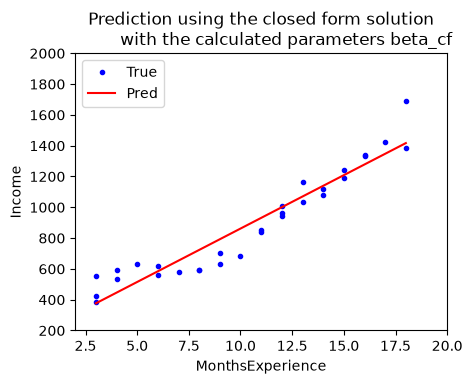

In [11]:
plt.xlim((2, 20))
plt.ylim((200, 2000))
plt.xlabel('MonthsExperience')
plt.ylabel('Income')
plt.title('''Prediction using the closed form solution
          with the calculated parameters beta_cf''')
plt.plot(df_blog['MonthsExperience'], df_blog['Income'], 'b.', label='True')
plt.plot(df_blog['MonthsExperience'], y_hat_cf, 'r-', label='Pred')
plt.legend()
plt.show()

### Exercise 1.4 - Final Answer

Let’s say you decide that you’re willing to give blogging 6 months of your time. At that point, if you’re not making any money, you call it quits. Use the simple linear model implemented in the previous exercise to calculate the expected income after 6 months of blogging.

We have already calculated the parameters in the asserts to the previous exercise and stored them in the variable `beta_cf`, but let's do it again just to practice.

In [12]:
# Create the input variables for the closed_form_solution function
x_simple = df_blog['MonthsExperience'].to_numpy()
y_simple = df_blog['Income'].to_numpy()

# Calculate the betas again
beta_simple = closed_form_solution(x_simple, y_simple)

In [13]:
# Now, use the calculated betas and the simple linear regression function from above 
# to calculate the predicted income at 6 months of blogging.
# Mind the type of the input parameters!
# y_hat_simple = ...
# YOUR CODE HERE
y_hat_simple = simple_linear_regression(np.array([6]), np.array(beta_simple))[2]

print('After 6 months in blogging, you will make: {} €'.format(round(y_hat_simple[0], 2))) 

After 6 months in blogging, you will make: 584.44 €


In [14]:
assert isinstance(y_hat_simple, np.ndarray), 'The output should be a numpy array'
# Check the error between the prediction and the real values at 6 months
np.testing.assert_array_almost_equal(cost_function(df_blog[df_blog.MonthsExperience==6].Income.mean(), y_hat_simple), 36.78,
                                     decimal=2,err_msg='The calculated value is not correct.') 

![mission](media/rich.gif)

So, maybe blogging isn't a very profitable job in a short/medium-term, at least....

## Exercise 2. Multiple Linear Regression

In this section, we will upgrade  to a linear regression with multiple features. We will use a very specific scenario, so that we are able to visualize it better - we will try to model a polynomial function, in particular a cubic function, which can be written as:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^{2} + \beta_3 x^{3}$$

You will basically be considering each power of x as a different feature. To simplify, we are going to construct a dataset with the powers we need:

In [15]:
x = 2 - 3 * np.random.normal(0, 1, 20)
y = x - 2 * (x ** 2) + 0.5 * (x ** 3) + np.random.normal(-3, 3, 20)

# transform the data to include another axis
x = x[:, np.newaxis]
y = y[:, np.newaxis]

polynomial_features = PolynomialFeatures(degree=3)
x_poly = polynomial_features.fit_transform(x)

data_ml = pd.DataFrame(x_poly, columns=['x1', 'x2', 'x3', 'x4']).drop(['x1'], axis=1)
data_ml.columns = ['x0', 'x1', 'x2']
data_ml['y'] = pd.DataFrame(y)[0]
data_ml.head()

,x0,x1,x2,y
0,0.509858,0.259955,0.132540,1.453164
1,2.414793,5.831225,14.081200,-5.884385
2,0.056934,0.003242,0.000185,-2.746872
3,-2.569090,6.600221,-16.956559,-31.522056
4,2.702460,7.303291,19.736852,-6.668844


Let's plot our data:

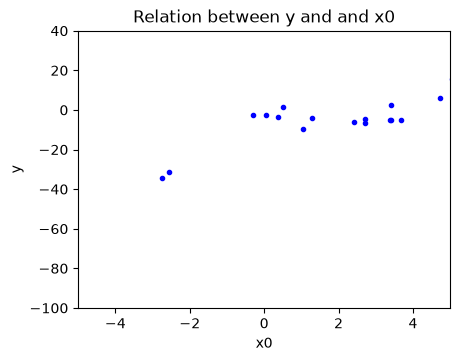

In [16]:
data_ml = data_ml.sort_values('x0')
plt.xlim((-5, 5))
plt.ylim((-100, 40))
plt.xlabel('x0')
plt.ylabel('y')
plt.title('Relation between y and and x0')
plt.plot(data_ml['x0'], data_ml['y'], 'b.')
plt.show()

Although this model is non-linear in its features, notice that it is linear with respect to the parameters, and the equation above can be rewritten as

$$\hat{y} = \beta_0 + \beta_1 x_0 + \beta_2 x_1 + \beta_3 x_2$$

where $[x_0, x_1, x_2]$ is our feature vector for a given sample.


### Exercise 2.1  Linear Model Extended

The multiple linear regression problem is just the linear regression problem with more than one feature. Let's recall the expression:

$$\hat{y} = \beta_0 + \sum_{i=1}^K \beta_i x_i$$

We can also write it in matrix form to consider several samples, as before:

$$\vec{\hat{y}} = \beta_0\vec{1} + X' \vec{\beta'_{1-k}}$$

where $X'$ is now a matrix containing all k features for all n samples: 

$$ X' = \begin{bmatrix} 
x_1^1 & x_2^1 & ... & x_k^1 \\
x_1^2 & x_2^2 & ... & x_k^2 \\
... & ... & ... & ...\\
x_1^n & x_2^n & ... & x_k^n \\
\end{bmatrix} $$

As before in the learning notebook, we can include also the intercept into the samples matrix and the parameter vector for a neater look and easier manipulation:

$$ X = [\vec{1} | X'] $$

and rewrite as

$$\vec{\hat{y}} = X \vec{\beta}$$

where $\vec{\beta}$ is now the full parameter vector including the intercept.

Implement this linear model for multiple features in the function below. Remember that the matrix dimensions must match in matrix concatenation and multiplication.

In [17]:
def extended_linear_model(x, betas):
    """
    Args:
        x : numpy.array with shape (num_samples, num_features) - features of the samples
        betas : numpy.array with shape (num_features + 1,) - parameters of 
                our model, with the intercept in the first position of 
                the array
    
    Returns:
        y_pred : numpy.array with shape (num_samples, ) - prediction 
                made by the multiple linear regression.
    """
    
    # We do the proper reshaping of the parameter vector into a column vector
    # so you don't have to worry about that and focus on the remaining logic
    betas = betas.reshape((-1, 1))
    
    # Extend the features matrix with a column of ones
    # X_mat = ...
    # YOUR CODE HERE
    X_mat = np.hstack((np.ones((x.shape[0], 1)), x))

    # Compute the output of the linear model
    # y_pred = ...
    # YOUR CODE HERE
    y_pred = X_mat @ betas
    
    # Now we again reshape the output for you
    return y_pred.flatten()

In [18]:
# Simple test
np.testing.assert_array_almost_equal(
    extended_linear_model(np.arange(0, 10).reshape(-1, 1), np.array([-12, 30])), 
    [-12.,  18.,  48.,  78., 108., 138., 168., 198., 228., 258.])
np.testing.assert_array_almost_equal(
    extended_linear_model(np.arange(-5, 5).reshape(-1, 1), np.array([1, 1])), 
    [-4., -3., -2., -1.,  0.,  1.,  2.,  3.,  4.,  5.])
np.testing.assert_array_almost_equal(
    extended_linear_model(np.arange(-10, 10, 2).reshape(-1, 1), np.array([0.25, 2.1])), 
    [-20.75, -16.55, -12.35, -8.15, -3.95, 0.25, 4.45, 8.65, 12.85, 17.05])

In [19]:
# Test with multiple features
np.testing.assert_array_almost_equal(
    extended_linear_model(np.array([[1., 2.], [3., 4.], [5., 6.]]), np.array([-1., 0., 1.])), 
    [1., 3., 5.])
np.testing.assert_array_almost_equal(
    extended_linear_model(np.ones((10, 2)), np.array([1., 2., 3.])), 
    [6., 6., 6., 6., 6., 6., 6., 6., 6., 6.])

### Mean Squared Error

As before, we can use the mean squared error to calculate the cost function. However, since this function does not receive anything other than the predictions and true values, there is no need to reimplement it. As before, let's see how large is the error if we pick random parameter values:

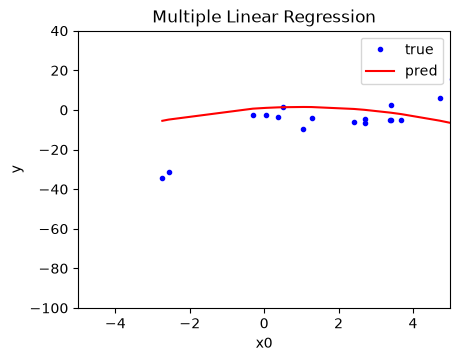

Error: 1773.6270396915643


In [20]:
# Error in our dataset with random parameter values
x_pln_rnd = data_ml['x0']
X_pln_rnd = data_ml.drop('y', axis=1).to_numpy()
y_pln_rnd = data_ml['y'].to_numpy()
# Create random parameter values
beta_pln_rnd = np.array([1., 1., -.5, 0.])
y_hat_pln_rnd = extended_linear_model(X_pln_rnd, beta_pln_rnd)

# Plot the data and the model output
plt.xlim((-5, 5))
plt.ylim((-100, 40))
plt.xlabel('x0')
plt.ylabel('y')
plt.title('Multiple Linear Regression')
plt.plot(x_pln_rnd, y_pln_rnd, 'b.', label='true')
plt.plot(x_pln_rnd, y_hat_pln_rnd, 'r-', label='pred')
plt.legend()
plt.show()

print('Error: {}'.format(cost_function(y_pln_rnd, y_hat_pln_rnd))) 

As you can see, the solution is clearly not a fit and the error is very high. So let's move into our closed form solution.

### Exercise 2.2 - Closed Form Solution

Let's now implement the closed form solution for the multiple linear regression. Remember that the solution in matrix form looks like this:

$$ \vec{\beta} = (X^TX)^{-1}(X^T\vec{y})$$

where X is the matrix of samples extended by a column of 1s, $X = [\vec{1} | X] $ , $\vec{y}$ is the vector of true sample values and $\vec{\beta}$ the vector of parameters $\beta_0$ - $\beta_k$

Implement the closed form solution for the multiple linear regression problem below.

In [21]:
def extended_closed_form_solution(x, y):
    """
    Args: 
        x : numpy.array with shape (num_samples, num_features) - features of the samples
        y : numpy.array with shape (num_samples, ) - true values of the samples
    
    Returns:
        betas : numpy.array with shape (num_features + 1, ) - parameter vector 
    """ 
    
    # Proper reshaping of the sample values
    y = y.reshape((-1, 1))

    # Extend the features matrix with a column of ones
    # X_extended = ...
    # YOUR CODE HERE
    X_extended = np.hstack((np.ones((x.shape[0], 1)), x))
    
    # Compute betas
    # YOUR CODE HERE
    betas = np.linalg.inv(X_extended.T @ X_extended) @ (X_extended.T @ y)
    
    # Once again, we reshape your array to get the proper output
    return betas.flatten()

In [22]:
# Simple tests
np.testing.assert_array_almost_equal(
    extended_closed_form_solution(np.arange(0, 10).reshape(10, 1), np.arange(0, 20, 2).reshape(10, 1)),
    [0., 2.])
np.testing.assert_array_almost_equal(
    extended_closed_form_solution(np.arange(-2, 3).reshape(5, 1), np.array([-1.25, -.5, .25, 1., 1.75]).reshape(5, 1)),
    [.25, .75])

# Extended test cases
np.testing.assert_array_almost_equal(
    extended_closed_form_solution(np.array([[1., -1.], [2., 1.], [3., -5.]]), np.array([0., 1., 0.])), 
    [-0.25, 0.5, 0.25])
np.testing.assert_array_almost_equal(
    extended_closed_form_solution(np.array([[10., -2.], [-4., 5.], [-7., -8.]]), np.array([2., 1., -.5])), 
    np.array([1.019704, 0.115764, 0.08867]))

Now apply the closed form solution to our dataset to get the best parameters and measure the error across the dataset:

In [23]:
x_pln_cf = data_ml['x0'].to_numpy()
y_pln_cf = data_ml['y'].to_numpy()

# All columns except y
X_pln_cf = data_ml.drop('y', axis=1).to_numpy()

beta_pln_cf = extended_closed_form_solution(X_pln_cf, y_pln_cf)
y_hat_pln_cf = extended_linear_model(X_pln_cf, np.array(beta_pln_cf))

assert math.isclose(cost_function(y_pln_cf, y_hat_pln_cf), 7.159451499759534), "Check your closed form function!"
print('The betas for our dataset:')
print(beta_pln_cf)

The betas for our dataset:
[-3.38747029  1.42581684 -2.21735123  0.52145858]


Finally, we plot the solution to see how it fits the data:

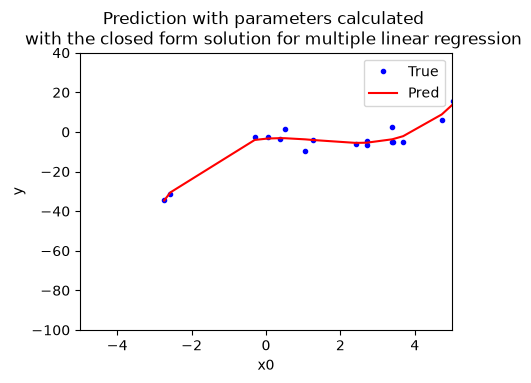

In [24]:
plt.xlim((-5, 5))
plt.ylim((-100, 40))
plt.xlabel('x0')
plt.ylabel('y')
plt.title('''Prediction with parameters calculated 
   with the closed form solution for multiple linear regression''')
plt.plot(x_pln_cf, y_pln_cf, 'b.', label='True')
plt.plot(x_pln_cf, y_hat_pln_cf, 'r-', label='Pred')
plt.legend()
plt.show()

Much better! It's a much better fit.

![reaction](media/reaction.gif)

## Exercise 3 . ScikitLearn Linear Regression

Luckily, ScikitLearn already provides us with a solver for the Linear Regression problem, which implements a closed form solution internally. It also provides some extra error measures such as the $R^2$ score. 
 
For this exercise, we'll be using the [California housing dataset](https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset) and try to model the house pricing based on the provided features. Start by loading and looking into the dataset. The dataset is scaled so that we can meaningfully compare the feature importance and also use it for gradient descent later on.

In [25]:
data = pd.read_csv('data/california_scaled.csv')
data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price100k
0,-1.434145,0.653481,-0.355032,-0.122859,-1.142169,0.259301,1.407459,-1.015334,-1.231887
1,1.148541,-0.974930,1.954681,-0.269657,0.439081,0.496947,-1.148566,1.247497,1.056991
2,4.643679,0.002117,1.577539,-0.242061,0.956385,-0.220944,-0.660598,0.509945,2.471630
3,1.286480,0.164958,0.862271,-0.565504,-0.964193,0.047019,0.826544,-1.251150,1.272112
4,0.798062,-0.974930,0.239860,-0.212041,2.395841,-0.325498,-0.609477,0.459771,0.549308


In [26]:
# All features except house price
columns_housing = data.drop(['Price100k','Latitude','Longitude'], axis=1)
x_housing = columns_housing.to_numpy()

# House price 
y_housing = data['Price100k'].to_numpy()

Each of the columns in the table is a feature that we're going to input into our model. Implement the function below to fit the provided data with the `sklearn.linear_model.LinearRegression` module that you've learned about. The function should return the fitted coefficients and the intercept, and the $R^2$ score. Check the reference guide if you need.

In [27]:
def sklearn_model_regression(x, y):
    """
    Fits the sklearn linear regression model to the provided data and 
    returns the fitted parameters and the R2 score.
    
    Args: 
        x: numpy.ndarray with shape (num_samples, num_features) - features of the samples
        y: numpy.array with shape (num_samples, ) - true values of the samples
        
    Return:
        coefs: numpy.array (num_features,) - coefficients vector
        intercept: float - intercept value
        score: float - R squared score of regression
    """

    # Fit the linear regressor
    # lr = ...
    # YOUR CODE HERE
    lr = LinearRegression().fit(x, y)
    
    # Extract the coefficients
    # coefs = ...
    # YOUR CODE HERE
    coefs = lr.coef_
    
    # Extract the intercept
    # intercept = ...
    # YOUR CODE HERE
    intercept = lr.intercept_
    
    # Calculate the R2 score
    # score = ...
    # YOUR CODE HERE
    score = lr.score(x, y)

    return coefs, intercept, score

Let's see what are our coefficients for each of the features.

In [28]:
coefs_housing, intercept_housing, score_housing = sklearn_model_regression(x_housing, y_housing)

print('Feature coefficients: ')
print(pd.Series(coefs_housing, columns_housing.columns))
print('\n')

print('Intercept: {}'.format(intercept_housing))
print('\n')

print('R² score: {}'.format(score_housing))

Feature coefficients: 
MedInc        0.893169
HouseAge      0.163779
AveRooms     -0.305439
AveBedrms     0.203096
Population    0.061075
AveOccup     -0.252201
dtype: float64


Intercept: 5.735719298620202e-16


R² score: 0.5996638585542686


Finally, check that your solution is an approximate of the true solution for the following tests:

In [29]:
betas_housing = np.concatenate((np.array([intercept_housing]), np.array(coefs_housing)), axis=0)

np.testing.assert_array_almost_equal(
    extended_linear_model(x_housing[:10], betas_housing),
    np.array([-1.22557268,  0.11585174,  3.73106594,  0.72709071,  0.6652216 ,
       -0.30509711, -0.07626561, -0.27029226,  0.78532166, -1.30559169]),
    decimal=2, err_msg='The calculated betas are not correct.')

np.testing.assert_array_almost_equal(
    extended_linear_model(x_housing[-10:], betas_housing),
    np.array([ 0.36492159, -0.31943796, -0.27246927, -0.13630818,  2.38036882,
        0.27150915, -0.67166059, -0.46275535, -0.66935684,  0.21438923]),
    decimal=2, err_msg='The calculated betas are not correct.')

y_hat_housing = extended_linear_model(x_housing, betas_housing)
np.testing.assert_allclose(cost_function(y_housing, y_hat_housing), 0.4003, atol=1e-3)

Last one before you go home!

![tired](media/tired.gif)

## Exercise 4. Gradient Descent

Now we will see how to get to a similar solution through learning/optimization methods. In this section, you will implement gradient descent. This method is an iterative process that finds the best betas in stepwise process. In each step, it updates the parameters in the direction that minimizes the error given by the cost function. For this, it makes use of derivatives according to the following formula:

$$ \vec{\beta}_{i+1} = \vec{\beta}_i - \eta \Delta_\vec{\beta} J$$

where $\Delta_\vec{\beta}$ is the vector of the derivatives - also called gradients - of the cost function with respect to the parameters, $\beta_{i+1}$ is the updated parameter and $\beta_{i}$ the current parameter. Therefore, we need to be able to compute these gradients to be able to update the parameters.

### Multiple Linear Regression partial derivatives

The vector $\Delta_\vec{\beta}$ in the formula above is just a vector with the partial derivatives of the cost function with respect to each of the parameters. The formulas for these partial derivatives with respect to each parameter are defined as follows:

$$\frac{\partial J}{\partial b_0} = - \frac{1}{N} \sum_{n=1}^N 2(y_n - \hat{y}_n) $$

$$\frac{\partial J}{\partial b_1} = - \frac{1}{N} \sum_{n=1}^N 2(y_n - \hat{y}_n)x_{1_n} $$

$$...$$

$$\frac{\partial J}{\partial b_K} = - \frac{1}{N} \sum_{n=1}^N 2(y_n - \hat{y}_n)x_{K_n} $$

Since the focus of this notebook is for you to implement the methods to solve linear regression, and you already have finished quite a great deal of work, we'll solve this one for you. Check below the code for the derivatives:

In [30]:
def linear_regression_partial_derivatives(x, y, y_hat):
    """
    Args:
        x : numpy.array with shape (num_samples, num_features) - features of the samples
        y : numpy.array with shape (num_samples,) - true values of the samples
        y_hat : numpy.array with shape (num_samples,) - predicted values of the samples
    
    Returns:
        deltas : numpy.array with shape (num_features + 1,)
            
    """    

    # Compute the difference between the targets and the predictions.
    y_diff = y - y_hat
    
    # Initialize the numpy array of partial derivatives
    deltas = np.zeros((x.shape[1] + 1, ))
    
    # Compute the partial derivative for b0
    deltas[0] = -(2 * y_diff).mean()
    
    # Extract the partial derivatives of the remaining betas  
    for col in range(x.shape[1]): 
        deltas[col+1] = -((2 * y_diff) * x[:, col]).mean()
    
    return deltas

### Exercise 4.1 Adjusting  parameters with gradient descent

Now we want to adjust the parameters with the update rule:

$$ \vec{\beta}_{i+1} = \vec{\beta}_i - \eta \Delta_\vec{\beta} J$$

where $\eta$ is our learning rate - how fast we want to move in the direction of the gradient. We will be implementing the standard gradient descent, also know as batch gradient descent, where for each iteration we will compute the derivatives for all the samples in the dataset.

1. _For epoch in 1...epochs:
    1. Predict the outputs with current parameters $\hat{y} = X \vec{\beta}_i$
    2. $\Delta_{\beta_0}J = -\frac{1}{N} \sum_{n=1}^N 2 (y - \hat{y})$
    3. $\Delta_{\beta_{i=1...N}}J = -\frac{1}{N} \sum_{n=1}^N 2 (y - \hat{y})x_{i_n} $
    4. $\beta_i = \beta_i - \eta \Delta_{\beta_i}$

Notice that you can get the gradients in steps B, C, and D with the function implemented above. Also note that steps B and C can be executed at the same time if you are using the extended forms of the feature matrix and the parameter vector.

The number of epochs and the learning rate will impact how fast we converge to the solution and how good the solution will be. Besides the number of epochs, there are more clever ways of knowing when to stop this procedure, but, for simplicity, we will only use this one here.

Implement this gradient descent function below.

In [31]:
def linear_regression_gradient_descent(x, y, betas, learning_rate, epochs): 
    """
    Args:
        x : numpy.array with shape (num_samples, num_features) - features of the samples
        y : numpy.array with shape (num_samples,)  - true values of the samples
        betas : numpy.array with shape (num_features + 1,) - initial parameters
        learning_rate : float - factor that will define the size of update step
        epochs : int - number of iterations

    Returns:
        betas : numpy.array with shape (num_features + 1) - final parameters
            
    """    

    for epoch in range(epochs): 

        # Compute estimates for this iteration 
        # y_hat = ...
        # YOUR CODE HERE
        y_hat = extended_linear_model(x, betas)

        # Compute the partial derivatives of the error function 
        # (hint: check linear_regression_partial_derivatives)
        # deltas = ...
        # YOUR CODE HERE
        deltas = linear_regression_partial_derivatives(x, y, y_hat)

        # Update betas with the Gradient Descent rule 
        # Hint: update all betas in one step
        # betas = ...
        # YOUR CODE HERE
        betas = betas - learning_rate * deltas
    
    return betas

In [32]:
np.random.seed(84)
betas = np.random.rand(x_housing.shape[1] + 1)
learning_rate = 0.1
epochs = 1

linear_regression_gradient_descent(x_housing, y_housing, betas, learning_rate, epochs)

array([0.03683279, 0.37950474, 0.28872774, 0.45251198, 0.765261  ,
       0.14199484, 0.11542501])

In [33]:
np.random.seed(42)
betas = np.random.rand(x_housing.shape[1] + 1)
learning_rate = 0.1
epochs = 10

betas_ = linear_regression_gradient_descent(x_housing, y_housing, betas, learning_rate, epochs)
np.testing.assert_array_almost_equal(
    betas_, 
    np.array([ 0.04021594,  0.67406805,  0.33511679,  0.03024199,  0.06876607,0.14584739, -0.23413881]),
    decimal=4)

np.random.seed(84)
betas = np.random.rand(x_housing.shape[1] + 1)
learning_rate = 0.1
epochs = 1

betas_ = linear_regression_gradient_descent(x_housing, y_housing, betas, learning_rate, epochs)
np.testing.assert_array_almost_equal(
    betas_, 
    np.array([0.03683279, 0.37950474, 0.28872774, 0.45251198, 0.765261, 0.14199484, 0.11542501]),
    decimal=4)

In order to compare the coefficients between the closed form solution and the result from the sklearn model, run the following cells:

In [34]:
#Read Dataset
data = pd.read_csv('data/california_scaled.csv')
columns_housing = data.drop(['Price100k','Latitude','Longitude'], axis=1)
x_housing = columns_housing.to_numpy()
# House price 
y_housing = data['Price100k'].to_numpy()

np.random.seed(42)
betas = np.random.rand(x_housing.shape[1] + 1)
learning_rate = 0.1
epochs = 200

betas_ = linear_regression_gradient_descent(x_housing, y_housing, betas, learning_rate, epochs)
coefs_housing, intercept_housing, score_housing = sklearn_model_regression(x_housing, y_housing)

intercept_housing_sgd = betas_[0]
coefs_housing_sgd = betas_[1:]

series_sgd = pd.Series(coefs_housing_sgd, columns_housing.columns, name='SGD')
series_ols = pd.Series(coefs_housing, columns_housing.columns, name='OLS')

print('Feature coefficients: ')
print(pd.concat([series_sgd, series_ols], axis=1))
print('\n')

print('Intercept SGD: {}'.format(intercept_housing_sgd))
print('\n')

print('Intercept OLS: {}'.format(intercept_housing))
print('\n')

Feature coefficients: 
                 SGD       OLS
MedInc      0.893078  0.893169
HouseAge    0.163798  0.163779
AveRooms   -0.305329 -0.305439
AveBedrms   0.203032  0.203096
Population  0.061088  0.061075
AveOccup   -0.252214 -0.252201


Intercept SGD: 5.774535950373938e-16


Intercept OLS: 5.735719298620202e-16




Same results, as expected! If you like, test how many epochs are necessary for the gradient descent to get close to the results of the closed form solution.

This is it! The end of this learning unit! 

![sum](media/sum.gif)